### Setting up the binary asteroid system

Initial conditions from https://en.wikipedia.org/wiki/Dimorphos

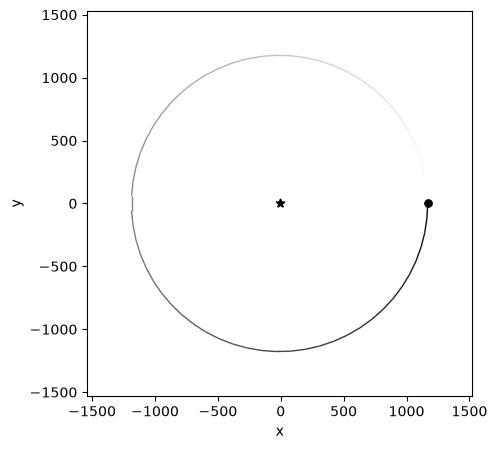

In [13]:
import rebound
import numpy as np
import matplotlib.pyplot as plt

sim = rebound.Simulation()

# Can change the integrator used
sim.integrator = "whfast"
#sim.integrator = "ias15"

# Changes units in simulation to SI units 
sim.G = 6.6743e-11 # m^3 / kg s^2

sim.add(m=5.2e11) # Didymos
sim.add(m=4.3e9, P=11.921473*60*60) # Dimorphos 

# Could also define Dimorphos using the semi-major axis, but the period is more precisely known

sim.move_to_com() 

%matplotlib inline
op = rebound.OrbitPlot(sim)

sim.dt = 0.0001

#sim.status()

### DART Impact

Modelling impact as a sudden force (momentum transfer) on Dimorphos 

https://rebound.hanno-rein.de/ipython_examples/Forces/

In the code, we can change the $c$ in $F_y = mc \implies c = F_y / m$

**Assuming a perfectly inelastic collision:**

$ m_s v_{i,s} + m_D v_{i,D} = m_s v_{f,s} + m_D v_{f,D} = (m_s + m_D) v_{f} $ 

$ \implies v_{f} = \frac{m_s v_{i,s} + m_D v_{i,D}}{m_s + m_D} $

$ a = \frac{v_f - v_i}{\Delta t} = -c $

In [14]:
# Time of impact
deltat = 0.5 # seconds

# Data taken from various papers 
v_f = (579.4 * 6.1449e3 + 4.3e9 * 0.177) / (579.4 + 4.3e9)

print("v_f =", v_f)
a = (v_f - 0.177) / deltat 
print("a =", a)

v_f = 0.17782796558755273
a = 0.001655931175105485


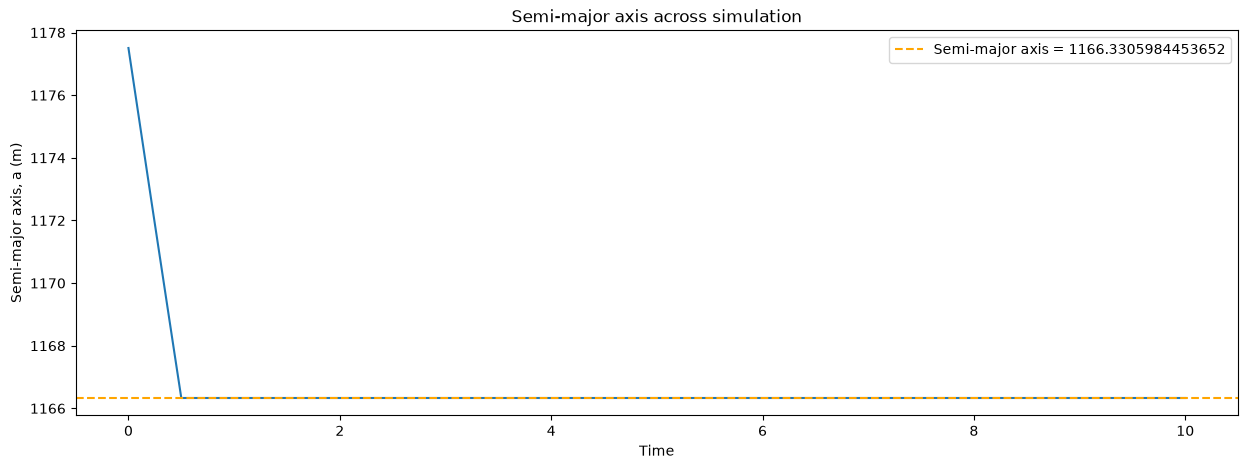

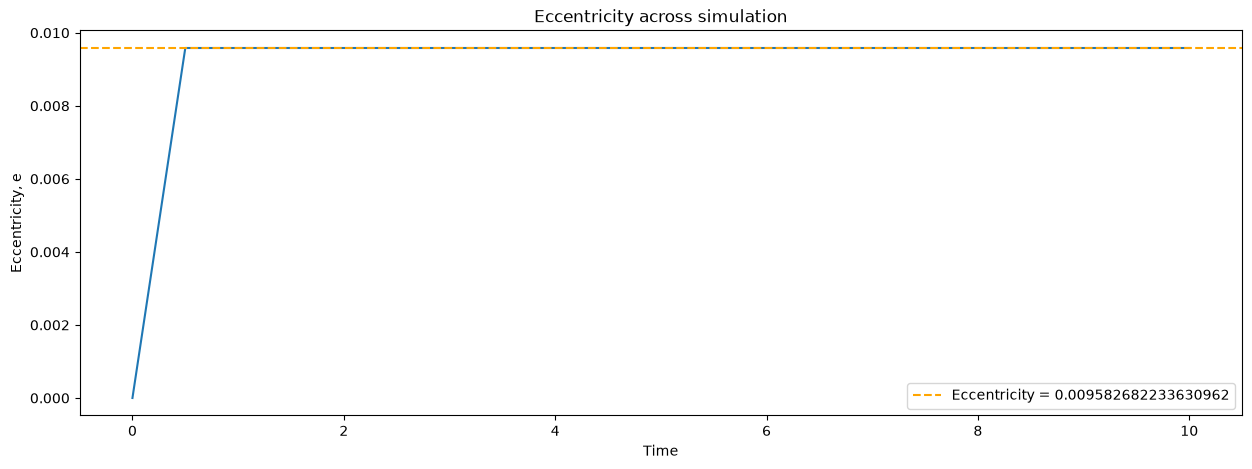

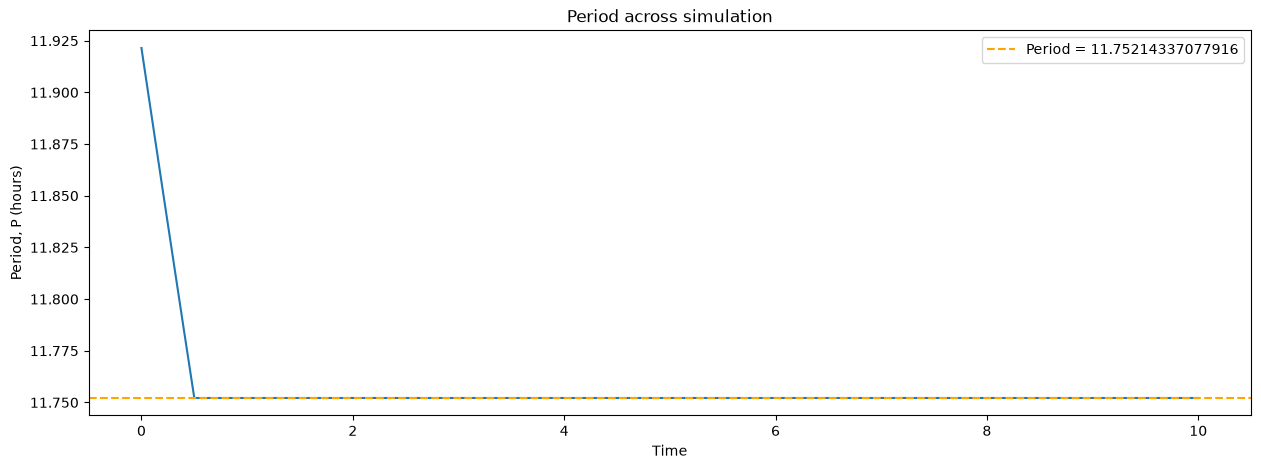

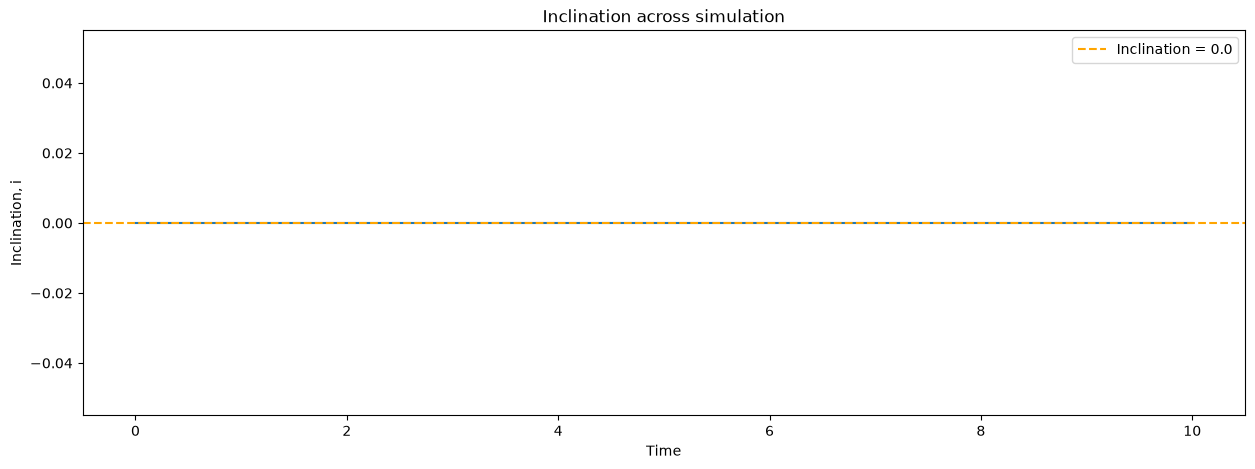

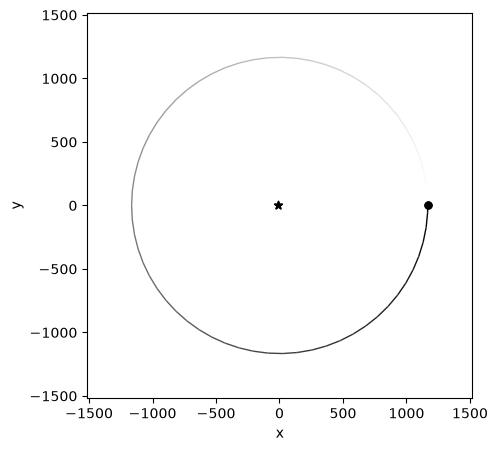

In [15]:
ps = sim.particles

# c is related to the force of the DART impact (see above)
c = -a 

def dart_impact(reb_sim):
    if sim.t <= deltat:
        ps[1].ay += c
    else: 
        ps[1].ay = 0 

sim.additional_forces = dart_impact

Nout = 10000
a_values = np.zeros(Nout)
eccentricity_values = np.zeros(Nout)
period_values = np.zeros(Nout)
inclination_values = np.zeros(Nout)

times = np.linspace(0, 0.001 * Nout, Nout)

for i, time in enumerate(times):
    sim.integrate(time, exact_finish_time=0) # integrate to the nearest timestep so timestep stays constant
    a_values[i] = sim.particles[1].a 
    eccentricity_values[i] = sim.particles[1].e
    period_values[i] = sim.particles[1].P
    inclination_values[i] = sim.particles[1].inc

# Plotting results 

%matplotlib inline
fig = plt.figure(figsize=(15,5))
ax = plt.subplot(111)
plt.plot(times, a_values)
plt.axhline(a_values[-1], label="Semi-major axis = "+str(a_values[-1]), color="orange", linestyle="--")
plt.xlabel("Time")
plt.ylabel("Semi-major axis, a (m)")
plt.title("Semi-major axis across simulation")
plt.legend()
plt.show()

%matplotlib inline
fig = plt.figure(figsize=(15,5))
ax = plt.subplot(111)
plt.plot(times, eccentricity_values)
plt.axhline(eccentricity_values[-1], label="Eccentricity = "+str(eccentricity_values[-1]), color="orange", linestyle="--")
plt.xlabel("Time")
plt.ylabel("Eccentricity, e")
plt.title("Eccentricity across simulation")
plt.legend()
plt.show()

%matplotlib inline
fig = plt.figure(figsize=(15,5))
ax = plt.subplot(111)

period_values_hours = np.array(period_values) / (60 * 60)

plt.plot(times, period_values_hours)
plt.axhline(period_values_hours[-1], label="Period = "+str(period_values_hours[-1]), color="orange", linestyle="--")
plt.xlabel("Time")
plt.ylabel("Period, P (hours)")
plt.title("Period across simulation")
plt.legend()
plt.show()

%matplotlib inline
fig = plt.figure(figsize=(15,5))
ax = plt.subplot(111)
plt.plot(times, inclination_values)
plt.axhline(inclination_values[-1], label="Inclination = "+str(inclination_values[-1]), color="orange", linestyle="--")
plt.xlabel("Time")
plt.ylabel("Inclination, i")
plt.title("Inclination across simulation")
plt.legend()
plt.show()

%matplotlib inline
op = rebound.OrbitPlot(sim)